# Nguyễn Thành Trí - MSSV: 6451071079

## Phần 2 - Bài 2 (Trang 37-38): Khai phá tập phổ biến & luật kết hợp dữ liệu Online Retail (UK)

Tập dữ liệu: `Online Retail.xlsx` (Thị trường United Kingdom)
Áp dụng thuật toán Apriori và FP-Growth với `min_sup = 3%` và `min_conf = 50%`.

## 1. CÂU 1: ĐỌC DỮ LIỆU ONLINE RETAIL

In [1]:
# Nguyễn Thành Trí - 6451071079
# Phần 2 - Bài 2 (Trang 37-38) - Câu 1: Đọc dữ liệu Online Retail

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file: {rel_path}")

file_path = get_data_path("Online Retail.xlsx")
print(f"Đang đọc dữ liệu từ: {file_path}...")
df = pd.read_excel(file_path)

print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột.")
print("\n5 dòng đầu tiên:")
display(df.head())

print("\nCấu trúc dữ liệu (df.info()):")
df.info()

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Đang đọc dữ liệu từ: ../../datasets/Online Retail.xlsx...


Kích thước tập dữ liệu: 541909 dòng, 8 cột.

5 dòng đầu tiên:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Cấu trúc dữ liệu (df.info()):
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


---\n## 2. CÂU 2: TIỀN XỬ LÝ DESCRIPTION VÀ INVOICENO

In [2]:
# Nguyễn Thành Trí - 6451071079
# Phần 2 - Bài 2 (Trang 37-38) - Câu 2: Tiền xử lý Description và InvoiceNo

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file: {rel_path}")

file_path = get_data_path("Online Retail.xlsx")
df = pd.read_excel(file_path)
print(f"Số dòng ban đầu: {len(df)}")

# 1. Cắt bỏ khoảng trắng thừa ở Description
df['Description'] = df['Description'].str.strip()

# 2. Xóa các dòng thiếu số hóa đơn (InvoiceNo rỗng/NaN)
df = df.dropna(subset=['InvoiceNo'])

# 3. Chuyển đổi InvoiceNo về kiểu chuỗi
df['InvoiceNo'] = df['InvoiceNo'].astype(str)

print(f"Số dòng sau khi làm sạch Description và lọc thiếu InvoiceNo: {len(df)}")
print("Kiểu dữ liệu cột InvoiceNo:", df['InvoiceNo'].dtype)
display(df.head())

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Số dòng ban đầu: 541909
Số dòng sau khi làm sạch Description và lọc thiếu InvoiceNo: 541909
Kiểu dữ liệu cột InvoiceNo: str


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


---\n## 3. CÂU 3: LOẠI BỎ HÓA ĐƠN HỦY/TÍN DỤNG (CHỨA 'C')

In [3]:
# Nguyễn Thành Trí - 6451071079
# Phần 2 - Bài 2 (Trang 37-38) - Câu 3: Loại bỏ các hóa đơn chứa ký tự 'C'

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file: {rel_path}")

file_path = get_data_path("Online Retail.xlsx")
df = pd.read_excel(file_path)
df['Description'] = df['Description'].str.strip()
df = df.dropna(subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)

total_before = len(df)
c_count = df['InvoiceNo'].str.contains('C').sum()

# Lọc bỏ hóa đơn chứa 'C'
df = df[~df['InvoiceNo'].str.contains('C')]
total_after = len(df)

print(f"Tổng số dòng trước khi lọc: {total_before}")
print(f"Số dòng hóa đơn hủy (chứa 'C'): {c_count} ({c_count/total_before*100:.2f}%)")
print(f"Số dòng hóa đơn mua hàng hợp lệ còn lại: {total_after}")
display(df.head())

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Tổng số dòng trước khi lọc: 541909
Số dòng hóa đơn hủy (chứa 'C'): 9288 (1.71%)
Số dòng hóa đơn mua hàng hợp lệ còn lại: 532621


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


---\n## 4. CÂU 4: THỐNG KÊ GIAO DỊCH THEO TỪNG QUỐC GIA

In [4]:
# Nguyễn Thành Trí - 6451071079
# Phần 2 - Bài 2 (Trang 37-38) - Câu 4: Thống kê theo từng quốc gia

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def load_clean_data():
    pkl_candidates = ["datasets/online_retail_clean.pkl", "../datasets/online_retail_clean.pkl", "../../datasets/online_retail_clean.pkl"]
    for p in pkl_candidates:
        if os.path.exists(p):
            return pd.read_pickle(p)
    file_path = "datasets/Online Retail.xlsx" if os.path.exists("datasets/Online Retail.xlsx") else "../datasets/Online Retail.xlsx"
    df = pd.read_excel(file_path)
    df['Description'] = df['Description'].str.strip()
    df = df.dropna(subset=['InvoiceNo'])
    df['InvoiceNo'] = df['InvoiceNo'].astype(str)
    return df[~df['InvoiceNo'].str.contains('C')]

df = load_clean_data()

country_counts = df['Country'].value_counts()
country_pct = (country_counts / len(df)) * 100
df_country = pd.DataFrame({'Số dòng giao dịch': country_counts, 'Tỷ lệ %': country_pct.round(2)})

print("Thống kê số dòng dữ liệu theo từng quốc gia (Top 15):")
display(df_country.head(15))

print(f"\nTổng số quốc gia có giao dịch: {len(df_country)}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Thống kê số dòng dữ liệu theo từng quốc gia (Top 15):


,Số dòng giao dịch,Tỷ lệ %
Country,,
United Kingdom,487622,91.55
Germany,9042,1.70
France,8408,1.58
EIRE,7894,1.48
Spain,2485,0.47
Netherlands,2363,0.44
Belgium,2031,0.38
Switzerland,1967,0.37
Portugal,1501,0.28



Tổng số quốc gia có giao dịch: 38


---\n## 5. CÂU 5: LỌC DỮ LIỆU NƯỚC ANH VÀ GOM NHÓM

In [5]:
# Nguyễn Thành Trí - 6451071079
# Phần 2 - Bài 2 (Trang 37-38) - Câu 5: Lọc nước Anh và gom nhóm dữ liệu

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def load_clean_data():
    pkl_candidates = ["datasets/online_retail_clean.pkl", "../datasets/online_retail_clean.pkl", "../../datasets/online_retail_clean.pkl"]
    for p in pkl_candidates:
        if os.path.exists(p):
            return pd.read_pickle(p)
    file_path = "datasets/Online Retail.xlsx" if os.path.exists("datasets/Online Retail.xlsx") else "../datasets/Online Retail.xlsx"
    df = pd.read_excel(file_path)
    df['Description'] = df['Description'].str.strip()
    df = df.dropna(subset=['InvoiceNo'])
    df['InvoiceNo'] = df['InvoiceNo'].astype(str)
    return df[~df['InvoiceNo'].str.contains('C')]

df = load_clean_data()

# Lọc dữ liệu Vương quốc Anh (United Kingdom)
df_uk = df[df['Country'] == 'United Kingdom']
print(f"Số dòng giao dịch tại United Kingdom: {len(df_uk)}")

# Gom nhóm Quantity theo InvoiceNo và Description
grouped = df_uk.groupby(['InvoiceNo', 'Description'])['Quantity'].sum()

print("\nKết quả gom nhóm (10 bản ghi mẫu):")
display(grouped.head(10))

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Số dòng giao dịch tại United Kingdom: 487622

Kết quả gom nhóm (10 bản ghi mẫu):


InvoiceNo  Description                        
536365     CREAM CUPID HEARTS COAT HANGER          8
           GLASS STAR FROSTED T-LIGHT HOLDER       6
           KNITTED UNION FLAG HOT WATER BOTTLE     6
           RED WOOLLY HOTTIE WHITE HEART.          6
           SET 7 BABUSHKA NESTING BOXES            2
           WHITE HANGING HEART T-LIGHT HOLDER      6
           WHITE METAL LANTERN                     6
536366     HAND WARMER RED POLKA DOT               6
           HAND WARMER UNION JACK                  6
536367     ASSORTED COLOUR BIRD ORNAMENT          32
Name: Quantity, dtype: int64

---\n## 6. CÂU 6: CHUYỂN ĐỔI VỀ DẠNG HOT ENCODING

In [6]:
# Nguyễn Thành Trí - 6451071079
# Phần 2 - Bài 2 (Trang 37-38) - Câu 6: Chuyển dữ liệu về dạng Hot Encoding

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def load_clean_data():
    pkl_candidates = ["datasets/online_retail_clean.pkl", "../datasets/online_retail_clean.pkl", "../../datasets/online_retail_clean.pkl"]
    for p in pkl_candidates:
        if os.path.exists(p):
            return pd.read_pickle(p)
    file_path = "datasets/Online Retail.xlsx" if os.path.exists("datasets/Online Retail.xlsx") else "../datasets/Online Retail.xlsx"
    df = pd.read_excel(file_path)
    df['Description'] = df['Description'].str.strip()
    df = df.dropna(subset=['InvoiceNo'])
    df['InvoiceNo'] = df['InvoiceNo'].astype(str)
    return df[~df['InvoiceNo'].str.contains('C')]

df = load_clean_data()
df_uk = df[df['Country'] == 'United Kingdom']

# Xoay trục tạo ma trận giỏ hàng (Hot Encoding)
basket = (df_uk.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

print(f"Kích thước ma trận giỏ hàng (Hot Encoding): {basket.shape[0]} hóa đơn x {basket.shape[1]} mặt hàng.")
print("\nHiển thị một phần của ma trận (5 hóa đơn đầu tiên, 6 cột mặt hàng):")
display(basket.iloc[:5, :6])

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Kích thước ma trận giỏ hàng (Hot Encoding): 18667 hóa đơn x 4175 mặt hàng.

Hiển thị một phần của ma trận (5 hóa đơn đầu tiên, 6 cột mặt hàng):


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD
InvoiceNo,,,,,,
536365,0.0,0.0,0.0,0.0,0.0,0.0
536366,0.0,0.0,0.0,0.0,0.0,0.0
536367,0.0,0.0,0.0,0.0,0.0,0.0
536368,0.0,0.0,0.0,0.0,0.0,0.0
536369,0.0,0.0,0.0,0.0,0.0,0.0


---\n## 7. CÂU 7: CHUYỂN ĐỔI SANG ONE-HOT ENCODING

In [7]:
# Nguyễn Thành Trí - 6451071079
# Phần 2 - Bài 2 (Trang 37-38) - Câu 7: Chuyển sang dạng One-Hot Encoding

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def load_clean_data():
    pkl_candidates = ["datasets/online_retail_clean.pkl", "../datasets/online_retail_clean.pkl", "../../datasets/online_retail_clean.pkl"]
    for p in pkl_candidates:
        if os.path.exists(p):
            return pd.read_pickle(p)
    file_path = "datasets/Online Retail.xlsx" if os.path.exists("datasets/Online Retail.xlsx") else "../datasets/Online Retail.xlsx"
    df = pd.read_excel(file_path)
    df['Description'] = df['Description'].str.strip()
    df = df.dropna(subset=['InvoiceNo'])
    df['InvoiceNo'] = df['InvoiceNo'].astype(str)
    return df[~df['InvoiceNo'].str.contains('C')]

df = load_clean_data()
df_uk = df[df['Country'] == 'United Kingdom']

basket = (df_uk.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

# Chuyển đổi thành One-Hot Encoding (giá trị >= 1 thành True/1, <= 0 thành False/0)
basket_sets = (basket >= 1)

print("Cấu trúc và kiểu dữ liệu của ma trận One-Hot Encoding:")
print(f"Kích thước: {basket_sets.shape}")
print("Kiểu dữ liệu cột:", basket_sets.dtypes.iloc[0])

print("\nHiển thị một phần của ma trận One-Hot (5 hóa đơn đầu tiên, 6 mặt hàng):")
display(basket_sets.iloc[:5, :6])

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Cấu trúc và kiểu dữ liệu của ma trận One-Hot Encoding:
Kích thước: (18667, 4175)
Kiểu dữ liệu cột: bool

Hiển thị một phần của ma trận One-Hot (5 hóa đơn đầu tiên, 6 mặt hàng):


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD
InvoiceNo,,,,,,
536365,False,False,False,False,False,False
536366,False,False,False,False,False,False
536367,False,False,False,False,False,False
536368,False,False,False,False,False,False
536369,False,False,False,False,False,False


---\n## 8. CÂU 8: XÓA CỘT CƯỚC PHÍ BƯU ĐIỆN 'POSTAGE'

In [8]:
# Nguyễn Thành Trí - 6451071079
# Phần 2 - Bài 2 (Trang 37-38) - Câu 8: Xóa cột 'POSTAGE'

import os
import pandas as pd
import numpy as np

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def load_clean_data():
    pkl_candidates = ["datasets/online_retail_clean.pkl", "../datasets/online_retail_clean.pkl", "../../datasets/online_retail_clean.pkl"]
    for p in pkl_candidates:
        if os.path.exists(p):
            return pd.read_pickle(p)
    file_path = "datasets/Online Retail.xlsx" if os.path.exists("datasets/Online Retail.xlsx") else "../datasets/Online Retail.xlsx"
    df = pd.read_excel(file_path)
    df['Description'] = df['Description'].str.strip()
    df = df.dropna(subset=['InvoiceNo'])
    df['InvoiceNo'] = df['InvoiceNo'].astype(str)
    return df[~df['InvoiceNo'].str.contains('C')]

df = load_clean_data()
df_uk = df[df['Country'] == 'United Kingdom']

basket = (df_uk.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket_sets = (basket >= 1)
print(f"Số lượng cột trước khi xóa POSTAGE: {basket_sets.shape[1]}")

# Xóa cột POSTAGE nếu có
if 'POSTAGE' in basket_sets.columns:
    basket_sets = basket_sets.drop(columns=['POSTAGE'])
    print("Đã xóa thành công cột 'POSTAGE'.")
else:
    print("Không tìm thấy cột 'POSTAGE' trong dữ liệu UK.")

print(f"Số lượng cột sau khi xử lý: {basket_sets.shape[1]}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Số lượng cột trước khi xóa POSTAGE: 4175
Đã xóa thành công cột 'POSTAGE'.
Số lượng cột sau khi xử lý: 4174


---\n## 9. CÂU 9: TÌM TẬP PHỔ BIẾN BẰNG APRIORI (min_sup = 3%)

In [9]:
# Nguyễn Thành Trí - 6451071079
# Phần 2 - Bài 2 (Trang 37-38) - Câu 9: Khai phá tập phổ biến bằng Apriori

import os
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import apriori

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def load_clean_data():
    pkl_candidates = ["datasets/online_retail_clean.pkl", "../datasets/online_retail_clean.pkl", "../../datasets/online_retail_clean.pkl"]
    for p in pkl_candidates:
        if os.path.exists(p):
            return pd.read_pickle(p)
    file_path = "datasets/Online Retail.xlsx" if os.path.exists("datasets/Online Retail.xlsx") else "../datasets/Online Retail.xlsx"
    df = pd.read_excel(file_path)
    df['Description'] = df['Description'].str.strip()
    df = df.dropna(subset=['InvoiceNo'])
    df['InvoiceNo'] = df['InvoiceNo'].astype(str)
    return df[~df['InvoiceNo'].str.contains('C')]

df = load_clean_data()
df_uk = df[df['Country'] == 'United Kingdom']

basket = (df_uk.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket_sets = (basket >= 1)
if 'POSTAGE' in basket_sets.columns:
    basket_sets = basket_sets.drop(columns=['POSTAGE'])

# Áp dụng thuật toán Apriori với min_support = 0.03 (3%)
frequent_itemsets = apriori(basket_sets, min_support=0.03, use_colnames=True)

# Thêm cột độ dài tập mục
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))
frequent_itemsets = frequent_itemsets.sort_values(by='support', ascending=False).reset_index(drop=True)

print(f"Tổng số tập mục phổ biến tìm thấy: {len(frequent_itemsets)}")
print(f"Phân loại theo kích thước tập mục:")
print(frequent_itemsets['length'].value_counts())

print("\nTop 10 tập mục phổ biến có độ hỗ trợ cao nhất:")
display(frequent_itemsets.head(10))

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Tổng số tập mục phổ biến tìm thấy: 131
Phân loại theo kích thước tập mục:
length
1    123
2      8
Name: count, dtype: int64

Top 10 tập mục phổ biến có độ hỗ trợ cao nhất:


,support,itemsets,length
0,0.116034,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
1,0.103820,frozenset({JUMBO BAG RED RETROSPOT}),1
2,0.090266,frozenset({REGENCY CAKESTAND 3 TIER}),1
3,0.085391,frozenset({PARTY BUNTING}),1
4,0.074570,frozenset({LUNCH BAG RED RETROSPOT}),1
5,0.073445,frozenset({ASSORTED COLOUR BIRD ORNAMENT}),1
6,0.066481,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN}),1
7,0.065302,frozenset({NATURAL SLATE HEART CHALKBOARD}),1
8,0.065142,frozenset({LUNCH BAG BLACK SKULL.}),1
9,0.062356,frozenset({HEART OF WICKER SMALL}),1


---\n## 10. CÂU 10: TẠO LUẬT KẾT HỢP VỚI min_conf = 50%

In [10]:
# Nguyễn Thành Trí - 6451071079
# Phần 2 - Bài 2 (Trang 37-38) - Câu 10: Sinh luật kết hợp với min_conf = 50%

import os
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import apriori, association_rules

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def load_clean_data():
    pkl_candidates = ["datasets/online_retail_clean.pkl", "../datasets/online_retail_clean.pkl", "../../datasets/online_retail_clean.pkl"]
    for p in pkl_candidates:
        if os.path.exists(p):
            return pd.read_pickle(p)
    file_path = "datasets/Online Retail.xlsx" if os.path.exists("datasets/Online Retail.xlsx") else "../datasets/Online Retail.xlsx"
    df = pd.read_excel(file_path)
    df['Description'] = df['Description'].str.strip()
    df = df.dropna(subset=['InvoiceNo'])
    df['InvoiceNo'] = df['InvoiceNo'].astype(str)
    return df[~df['InvoiceNo'].str.contains('C')]

df = load_clean_data()
df_uk = df[df['Country'] == 'United Kingdom']

basket = (df_uk.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket_sets = (basket >= 1)
if 'POSTAGE' in basket_sets.columns:
    basket_sets = basket_sets.drop(columns=['POSTAGE'])

frequent_itemsets = apriori(basket_sets, min_support=0.03, use_colnames=True)

# Tạo luật kết hợp với min_threshold = 0.5 (confidence >= 50%)
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)

# Định dạng hiển thị luật kết hợp
display_rules = rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].copy()
display_rules['antecedents'] = display_rules['antecedents'].apply(lambda x: ', '.join(list(x)))
display_rules['consequents'] = display_rules['consequents'].apply(lambda x: ', '.join(list(x)))
display_rules = display_rules.sort_values(by='confidence', ascending=False).reset_index(drop=True)

print(f"Tổng số luật kết hợp được sinh ra: {len(display_rules)}")
print("\nDanh sách các luật kết hợp (sắp xếp theo Confidence giảm dần):")
display(display_rules)

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Tổng số luật kết hợp được sinh ra: 10

Danh sách các luật kết hợp (sắp xếp theo Confidence giảm dần):


,antecedents,consequents,support,confidence,lift
0,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.030910,0.820768,16.403939
1,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.037553,0.750535,14.639752
2,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.037553,0.732497,14.639752
3,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,0.042053,0.677308,6.523895
4,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.030160,0.642694,12.900183
5,JUMBO BAG BAROQUE BLACK WHITE,JUMBO BAG RED RETROSPOT,0.030535,0.626374,6.033290
6,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.030910,0.617773,16.403939
7,JUMBO STORAGE BAG SUKI,JUMBO BAG RED RETROSPOT,0.037392,0.617699,5.949737
8,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.030160,0.605376,12.900183
9,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO BAG RED RETROSPOT,0.035196,0.579876,5.585425


---\n## 11. CÂU 11: BIỂU DIỄN ĐỒ THỊ PHÂN TÁN SUPPORT VS CONFIDENCE

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


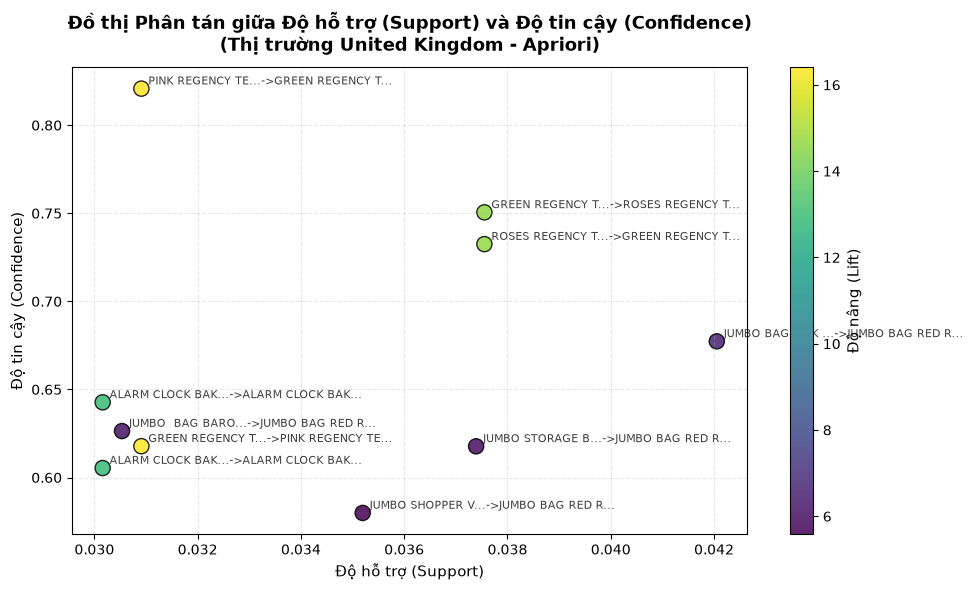

In [11]:
# Nguyễn Thành Trí - 6451071079
# Phần 2 - Bài 2 (Trang 37-38) - Câu 11: Đồ thị phân tán Support vs Confidence

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def get_img_dir(subpath=""):
    for base in [".", "..", "../.."]:
        img_root = os.path.join(base, "images")
        if os.path.exists(img_root) and (os.path.exists(os.path.join(base, "datasets")) or os.path.exists(os.path.join(base, "CLAUDE.md"))):
            target = os.path.join(img_root, subpath) if subpath else img_root
            os.makedirs(target, exist_ok=True)
            return target
    target = os.path.join("images", subpath) if subpath else "images"
    os.makedirs(target, exist_ok=True)
    return target
img_dir = get_img_dir("Phan2/Bai2")

def load_clean_data():
    pkl_candidates = ["datasets/online_retail_clean.pkl", "../datasets/online_retail_clean.pkl", "../../datasets/online_retail_clean.pkl"]
    for p in pkl_candidates:
        if os.path.exists(p):
            return pd.read_pickle(p)
    file_path = "datasets/Online Retail.xlsx" if os.path.exists("datasets/Online Retail.xlsx") else "../datasets/Online Retail.xlsx"
    df = pd.read_excel(file_path)
    df['Description'] = df['Description'].str.strip()
    df = df.dropna(subset=['InvoiceNo'])
    df['InvoiceNo'] = df['InvoiceNo'].astype(str)
    return df[~df['InvoiceNo'].str.contains('C')]

df = load_clean_data()
df_uk = df[df['Country'] == 'United Kingdom']

basket = (df_uk.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket_sets = (basket >= 1)
if 'POSTAGE' in basket_sets.columns:
    basket_sets = basket_sets.drop(columns=['POSTAGE'])

frequent_itemsets = apriori(basket_sets, min_support=0.03, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)

# Vẽ đồ thị phân tán Support vs Confidence
plt.figure(figsize=(10, 6))
scatter = plt.scatter(rules['support'], rules['confidence'], c=rules['lift'], cmap='viridis', s=120, alpha=0.85, edgecolors='k', linewidth=1)
cbar = plt.colorbar(scatter)
cbar.set_label('Độ nâng (Lift)', fontsize=11)

plt.title('Đồ thị Phân tán giữa Độ hỗ trợ (Support) và Độ tin cậy (Confidence)\n(Thị trường United Kingdom - Apriori)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Độ hỗ trợ (Support)', fontsize=11)
plt.ylabel('Độ tin cậy (Confidence)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.3)

# Đánh nhãn trực tiếp cho các điểm luật
for _, row in rules.iterrows():
    ant = list(row['antecedents'])[0][:15] + '...'
    con = list(row['consequents'])[0][:15] + '...'
    plt.annotate(f"{ant}->{con}", (row['support'], row['confidence']), fontsize=8, alpha=0.75, xytext=(5, 3), textcoords='offset points')

plt.tight_layout()
plt.savefig(os.path.join(img_dir, 'rules_scatter.png'), dpi=300, bbox_inches='tight')
plt.show()

---\n## 12. CÂU 12: KHAI PHÁ BẰNG FP-GROWTH VÀ SO SÁNH VỚI APRIORI

In [12]:
# Nguyễn Thành Trí - 6451071079
# Phần 2 - Bài 2 (Trang 37-38) - Câu 12: So sánh Apriori và FP-Growth

import os
import time
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def load_clean_data():
    pkl_candidates = ["datasets/online_retail_clean.pkl", "../datasets/online_retail_clean.pkl", "../../datasets/online_retail_clean.pkl"]
    for p in pkl_candidates:
        if os.path.exists(p):
            return pd.read_pickle(p)
    file_path = "datasets/Online Retail.xlsx" if os.path.exists("datasets/Online Retail.xlsx") else "../datasets/Online Retail.xlsx"
    df = pd.read_excel(file_path)
    df['Description'] = df['Description'].str.strip()
    df = df.dropna(subset=['InvoiceNo'])
    df['InvoiceNo'] = df['InvoiceNo'].astype(str)
    return df[~df['InvoiceNo'].str.contains('C')]

df = load_clean_data()
df_uk = df[df['Country'] == 'United Kingdom']

basket = (df_uk.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket_sets = (basket >= 1)
if 'POSTAGE' in basket_sets.columns:
    basket_sets = basket_sets.drop(columns=['POSTAGE'])

min_sup = 0.03
min_conf = 0.5

# 1. Đo lường Apriori
t0 = time.perf_counter()
frequent_itemsets_ap = apriori(basket_sets, min_support=min_sup, use_colnames=True)
rules_ap = association_rules(frequent_itemsets_ap, metric="confidence", min_threshold=min_conf)
time_ap = time.perf_counter() - t0

# 2. Đo lường FP-Growth
t0 = time.perf_counter()
frequent_itemsets_fp = fpgrowth(basket_sets, min_support=min_sup, use_colnames=True)
rules_fp = association_rules(frequent_itemsets_fp, metric="confidence", min_threshold=min_conf)
time_fp = time.perf_counter() - t0

# Bảng so sánh
comparison_df = pd.DataFrame({
    'Chỉ số so sánh': [
        'Số tập phổ biến tìm được',
        'Số luật kết hợp sinh ra',
        'Thời gian thực thi (giây)',
        'Phương pháp tiếp cận',
        'Chi phí bộ nhớ'
    ],
    'Thuật toán Apriori': [
        len(frequent_itemsets_ap),
        len(rules_ap),
        f"{time_ap:.4f} s",
        "Level-wise (Sinh ứng viên Ck)",
        "Quét CSDL nhiều lần"
    ],
    'Thuật toán FP-Growth': [
        len(frequent_itemsets_fp),
        len(rules_fp),
        f"{time_fp:.4f} s",
        "Divide-and-Conquer (FP-Tree)",
        "Nén toàn bộ CSDL vào cây FP-Tree"
    ]
})

print("BẢNG SO SÁNH HIỆU NĂNG GIỮA APRIORI VÀ FP-GROWTH:")
display(comparison_df)

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


BẢNG SO SÁNH HIỆU NĂNG GIỮA APRIORI VÀ FP-GROWTH:


,Chỉ số so sánh,Thuật toán Apriori,Thuật toán FP-Growth
0,Số tập phổ biến tìm được,131,131
1,Số luật kết hợp sinh ra,10,10
2,Thời gian thực thi (giây),0.4448 s,1.0240 s
3,Phương pháp tiếp cận,Level-wise (Sinh ứng viên Ck),Divide-and-Conquer (FP-Tree)
4,Chi phí bộ nhớ,Quét CSDL nhiều lần,Nén toàn bộ CSDL vào cây FP-Tree
